# 03 — Analysis

**Input:** `data/alignn_bulk_modulus_full_results.csv` produced by `02_run_alignn.ipynb`.

**Output:** every number and figure in the Results section of the paper.

**Runs on your laptop.** No GPU, no Colab, no model loading. Reading a CSV and
summarising it takes seconds, so this notebook can be rerun any time without
reinstalling anything.

**Kernel:** set it to your local Python (3.13.x), not a Colab server. If you
see "cannot find file", the kernel is probably pointing at a cloud machine that
cannot see your laptop's `data/` folder.

## 1. Load and prepare

Everything downstream depends on this cell, so it is written to rebuild the
full analysis state from the CSV alone. Run it once at the start of any session.

**The three derived columns:**

- `abs_error` — how far the prediction is from the DFT value, in GPa. Absolute,
  because a 5 GPa overestimate and a 5 GPa underestimate are equally wrong.
- `jid_num` — the number inside `"JVASP-7630"`. JARVIS assigns these roughly in
  the order materials enter the database, so they act as a rough timestamp.
- `group` — the three-way classification the whole analysis rests on.

**Why three groups and not two.** `was_seen` in the CSV is True for anything in
*any* published split, including the official test split. But the model was
never trained on test-split materials — they were held out by its authors. So
they must be separated:

| group | meaning | role |
|---|---|---|
| `train_val` | model learned from these | shows what memorisation looks like |
| `official_test` | held out by ALIGNN's authors | reproduces the published benchmark |
| `unseen` | in no split at all | the materials we care about |

The meaningful comparison is **official_test vs unseen** — the model trained on
neither, so any difference is about generalisation, not memorisation.

**Expect:** 25,506 rows before cleaning.

In [1]:
import pandas as pd

results_df = pd.read_csv("../data/alignn_bulk_modulus_full_results.csv")

results_df["abs_error"] = (results_df["predicted"] - results_df["dft"]).abs()
results_df["jid_num"]   = results_df["jid"].str.split("-").str[1].astype(int)

def group(row):
    if not row["was_seen"]:
        return "unseen"
    if row["in_test_set"]:
        return "official_test"
    return "train_val"

results_df["group"] = results_df.apply(group, axis=1)

print(f"rows: {len(results_df)}")
print(results_df["group"].value_counts())

rows: 25506
group
unseen           12753
train_val        11500
official_test     1253
Name: count, dtype: int64


## 2. Label screen

A bulk modulus says how hard a material is to compress. For a stable crystal it
must be positive — a value of zero or below is physically impossible and means
the DFT calculation failed or never converged.

`.copy()` matters here. Without it pandas returns a *view* into the original
table, and later edits raise `SettingWithCopyWarning` and may not stick.

**Expect:** 11,312 / 1,227 / 12,571 after cleaning.

| group | mean (GPa) | median (GPa) |
|---|---|---|
| train_val | 2.27 | 0.86 |
| official_test | 9.94 | 3.06 |
| unseen | 10.06 | 5.22 |

In [2]:
clean = results_df[results_df["dft"] > 0].copy()
print(f"removed {len(results_df) - len(clean)} non-positive entries")
print(clean.groupby("group")["abs_error"].agg(["count", "mean", "median"]))

removed 396 non-positive entries
               count       mean    median
group                                    
official_test   1227   9.942918  3.056837
train_val      11312   2.270149  0.864996
unseen         12571  10.056910  5.223327


### Reading that table

**The pipeline is validated.** `official_test` gives 9.94 GPa against ALIGNN's
published 9.89 GPa — a 0.5% difference. Our code reproduces the published
result, so nothing downstream is an artifact of a broken pipeline.

**train_val is low for an uninteresting reason.** The model was fitted to those
materials. Comparing training error to test error tells you nothing — every
model does better on data it was trained on.

**The real result is in the last two rows.** Mean errors are nearly identical
(9.94 vs 10.06) but median errors differ by a factor of 1.7 (3.06 vs 5.22).
Same average, different typical case.

## 3. Where in the distribution the difference lies

The mean and median disagree, so look at the whole distribution rather than one
summary number. Percentiles answer "what error is the model within, for this
fraction of materials?"

**Expect:**

| percentile | official_test | unseen | ratio |
|---|---|---|---|
| 25th | 1.06 | 1.99 | 1.9 |
| 50th | 3.06 | 5.22 | 1.7 |
| 75th | 8.10 | 11.56 | 1.4 |
| 90th | 18.80 | 22.60 | 1.2 |
| 95th | 41.10 | 33.62 | **0.8** |

The gap is largest for the materials the model handles best, shrinks steadily,
and **reverses at the 95th percentile**. The test set contains both more very
easy cases and some worse failures. The two effects cancel in the mean, which
is exactly why the means agree while the medians do not.

In [3]:
print(clean.groupby("group")["abs_error"]
      .quantile([0.25, 0.5, 0.75, 0.9, 0.95]).unstack())

                   0.25      0.50       0.75       0.90       0.95
group                                                             
official_test  1.057707  3.056837   8.104401  18.800845  41.103050
train_val      0.381289  0.864996   1.771685   3.414731   6.158254
unseen         1.989002  5.223327  11.556702  22.598019  33.619495


## 4. Is the difference real?

A reviewer will ask whether 1.7x could be chance.

**Mann-Whitney U** compares two groups by ranking all their values together and
asking whether one group's values tend to sit higher. It makes no assumption
that the data follow a bell curve — important here, since absolute errors are
strongly right-skewed.

`alternative="greater"` tests specifically whether unseen errors exceed
official-test errors, rather than merely differing.

**Expect:** p = 3.75e-27.

**Interpreting it honestly:** with ~12,500 and ~1,200 samples, even a tiny
difference would reach significance. The p-value says the difference is real;
the **1.7x effect size** says it matters. Report both, and lead with the
effect size.

In [4]:
from scipy.stats import mannwhitneyu

test_err   = clean[clean["group"] == "official_test"]["abs_error"]
unseen_err = clean[clean["group"] == "unseen"]["abs_error"]

stat, p = mannwhitneyu(unseen_err, test_err, alternative="greater")
print(f"p-value: {p:.2e}")

p-value: 3.75e-27


## 5. Were the unseen materials really added later?

The paper claims unseen materials post-date the model's release. That was an
assumption, so it needs evidence.

JARVIS identifiers are assigned roughly in order of entry, so they act as a
rough timestamp. If the claim holds, unseen materials should carry higher IDs.

**Expect:** median ID 176,501 for unseen against 37,167 for seen; and the
highest seen ID is 123,009, while 12,653 of 12,753 unseen materials (99.2%)
exceed it.

That means over 99% of unseen materials sit entirely beyond every material the
model was trained or tested on.

**The honest caveat:** ID order is a proxy for date, not a record of it. 100
unseen materials (0.8%) have low IDs and so predate the splits, left out for
some other reason. Section 6 checks whether they matter.

In [5]:
print(results_df.groupby("was_seen")["jid_num"].describe())

max_seen = results_df[results_df["was_seen"]]["jid_num"].max()
unseen   = results_df[~results_df["was_seen"]]
n_later  = (unseen["jid_num"] > max_seen).sum()

print(f"\nHighest seen ID: {max_seen}")
print(f"Unseen above it: {n_later} of {len(unseen)} ({100*n_later/len(unseen):.1f}%)")

            count           mean           std    min       25%       50%  \
was_seen                                                                    
False     12753.0  168163.827021  20850.081276  801.0  151837.0  176501.0   
True      12753.0   49874.439034  38429.383591    5.0   16227.0   37167.0   

               75%       max  
was_seen                      
False     186536.0  194938.0  
True       79816.0  123009.0  

Highest seen ID: 123009
Unseen above it: 12653 of 12753 (99.2%)


## 6. Robustness check

Restrict the unseen group to materials whose IDs exceed every ID in any split,
removing the 100 ambiguous cases entirely. This is the strictest possible
version of the analysis — no material here could have existed when the model
was trained.

**Expect:** n = 12,482, mean 10.00 GPa, median 5.22 GPa.

The median is unchanged to two decimal places. The ambiguous materials were not
driving anything, so the result stands on the cleanest subset available.

In [6]:
later = clean[(clean["group"] == "unseen") & (clean["jid_num"] > max_seen)]
print(later["abs_error"].agg(["count", "mean", "median"]))

count     12482.000000
mean          9.995978
median        5.216816
Name: abs_error, dtype: float64


## 7. Label quality across the splits

Section 2 removed non-positive entries from the analysis. This asks a separate
question: how many were there, and were they concentrated anywhere?

**Expect:** roughly 1.4-2.2% in every group — a similar rate throughout.

That uniformity matters for what you may claim. You **cannot** say the test set
was unfairly corrupted. You **can** say roughly 2% of labels in this benchmark
are unphysical, in training and evaluation alike.

The full database-wide audit (271 training entries, 44 test entries out of all
32,433 materials) lives in `01_build_dataset.ipynb`. This cell covers only the
25,506 materials actually predicted here.

In [7]:
bad = results_df[results_df["dft"] <= 0]
print(f"non-positive entries in this run: {len(bad)}")
print((bad["group"].value_counts() / results_df["group"].value_counts() * 100).round(2))

named = bad[bad["formula"].isin(["InSb", "GaAs", "InAs", "InP", "GaSb"])]
if len(named):
    print("\nWell-known compounds among them:")
    print(named[["jid", "formula", "dft", "predicted", "group"]])

non-positive entries in this run: 396
group
official_test    2.08
train_val        1.63
unseen           1.43
Name: count, dtype: float64

Well-known compounds among them:
              jid formula  dft  predicted      group
9110  JVASP-15902    InSb  0.0  -0.596574  train_val


## 8. The largest errors

Sorting by error reveals two very different failure types, which must not be
conflated.

**Type 1 — corrupted labels, not model errors.** Rows where the DFT value is
near zero and the prediction is 200+ GPa. MnBeTc2 (DFT 0.00, predicted 231.66)
and NbSiIr (DFT 3.12, predicted 233.88) are examples. Here the *model* is
probably right and the *database* is wrong. Six of the top twenty are like this.

**Type 2 — genuine model failures.** Rows where the DFT value looks sound but
the prediction is badly off. BeRu is the clearest: DFT 223.46 GPa, predicted
**-0.43 GPa** — a negative bulk modulus, which is physically impossible.
Nonphysical predictions of this kind are documented elsewhere in the
machine-learned potential literature.

The `dft_suspicious` column separates the two so they are never counted
together.

In [8]:
worst = results_df.sort_values("abs_error", ascending=False).head(20).copy()
worst["dft_suspicious"] = worst["dft"] < 5

print(worst[["jid", "formula", "dft", "predicted", "abs_error",
             "group", "dft_suspicious"]].to_string(index=False))
print(f"\nOf the 20 largest errors, {worst['dft_suspicious'].sum()} "
      f"have a suspect DFT label")

         jid    formula    dft  predicted  abs_error         group  dft_suspicious
 JVASP-70937    BeFeOs2 295.11   0.517007 294.592993 official_test           False
 JVASP-75622     ReAsW2 268.37  10.475911 257.894089     train_val           False
JVASP-185972    BeCoRu2 251.59   1.540583 250.049417        unseen           False
JVASP-111549     MnRuN2  30.22 271.773651 241.553651 official_test           False
JVASP-190548    Ta2CrOs 263.63  27.652819 235.977181        unseen           False
 JVASP-67671    MnBeTc2   0.00 231.664688 231.664688     train_val            True
 JVASP-36278       ErSb 300.30  69.139595 231.160405     train_val           False
 JVASP-23551     NbSiIr   3.12 233.882690 230.762690     train_val            True
JVASP-188311    BeCo2Ru 244.20  14.304052 229.895948        unseen           False
JVASP-189447     Ta2VOs 249.03  19.868696 229.161304        unseen           False
 JVASP-66860     BeMoRh 226.79   2.068930 224.721070 official_test           False
JVAS

## 9. Beryllium: a tail effect, not a general weakness

Eight of the twenty largest errors contain beryllium, which suggests a possible
failure mode. Checking it properly gives a more careful answer.

**Expect:**

| | count | mean | median |
|---|---|---|---|
| no Be | 23,467 | 6.38 | 2.03 |
| has Be | 1,643 | 8.82 | **1.73** |

Be-containing materials have a **higher mean but a lower median**. The typical
beryllium compound is predicted slightly *better* than average; they are simply
overrepresented among extreme failures.

So the honest statement is narrow: beryllium compounds are overrepresented in
the tail, not systematically harder. Writing "the model struggles with
beryllium" would be wrong, and the mean alone would have led there.

A neat echo of the main result: the mean and median disagree again, for the
same reason.

In [9]:
clean["has_Be"] = clean["formula"].str.contains("Be", na=False)
print(clean.groupby("has_Be")["abs_error"].agg(["count", "mean", "median"]))

        count      mean    median
has_Be                           
False   23467  6.384339  2.033116
True     1643  8.815583  1.730986


## 10. Figure 1 — cumulative error distribution

The clearest way to show the finding. At any point on a curve, the height is
the fraction of materials with error below that value.

- **Further left = more accurate**
- **Where a curve crosses the dotted line at 0.5 is that group's median**
- **The x-axis is logarithmic**, so horizontal distance is a *ratio*, not a
  difference

Look for the unseen curve sitting right of the official-test curve through most
of the range, then crossing near the top. That crossing is why the means match
while the medians do not — visible in a single glance.

Saved as both PNG (for drafts) and PDF (vector, for submission — journals
prefer it because it stays sharp at any size).

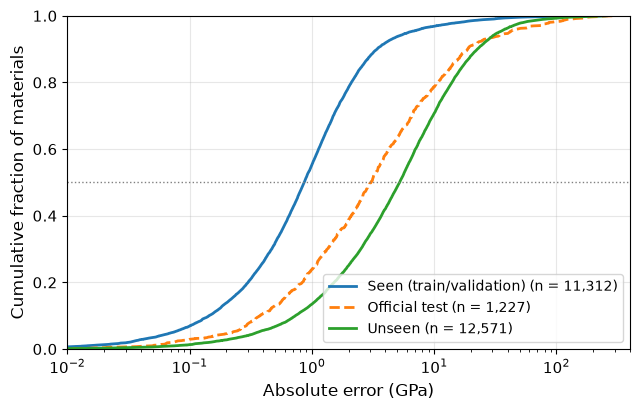

In [10]:
import os, numpy as np, matplotlib.pyplot as plt
os.makedirs("../figures", exist_ok=True)

labels = {"train_val": "Seen (train/validation)",
          "official_test": "Official test",
          "unseen": "Unseen"}
styles = {"train_val": "-", "official_test": "--", "unseen": "-"}

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for name in ["train_val", "official_test", "unseen"]:
    e = np.sort(clean[clean["group"] == name]["abs_error"].values)
    y = np.arange(1, len(e) + 1) / len(e)
    ax.plot(e, y, styles[name], lw=2, label=f"{labels[name]} (n = {len(e):,})")

ax.axhline(0.5, color="grey", ls=":", lw=1)
ax.set_xscale("log")
ax.set_xlim(1e-2, 400)
ax.set_ylim(0, 1)
ax.set_xlabel("Absolute error (GPa)", fontsize=12)
ax.set_ylabel("Cumulative fraction of materials", fontsize=12)
ax.tick_params(labelsize=11)
ax.grid(alpha=0.3)
ax.legend(fontsize=10, loc="lower right")
plt.tight_layout()
plt.savefig("../figures/figure1_error_cdf.png", dpi=300)
plt.savefig("../figures/figure1_error_cdf.pdf")
plt.show()

## 11. Save the derived tables

Writes out the cleaned dataset and the worst-error table, so the paper's tables
can be built without rerunning anything.

In [11]:
os.makedirs("../data", exist_ok=True)
clean.to_csv("../data/alignn_results_clean.csv", index=False)
worst.to_csv("../data/alignn_worst_errors.csv", index=False)
print("saved")

saved


---

## Summary of results

| Quantity | Value | Section |
|---|---|---|
| Reproduced benchmark (official test) | 9.94 GPa vs 9.89 published | 2 |
| Mean error, unseen | 10.06 GPa | 2 |
| Median error, official test vs unseen | 3.06 vs 5.22 GPa (1.7x) | 2 |
| Mann-Whitney p | 3.75e-27 | 4 |
| Unseen with ID above all splits | 12,653 / 12,753 (99.2%) | 5 |
| Strict-subset median | 5.22 GPa (unchanged) | 6 |
| Corrupted labels among top-20 errors | 6 of 20 | 8 |
| Beryllium | higher mean, lower median | 9 |

### Open items

- The official-test group is 1,227 of 1,968 materials, because the seen sample
  was drawn randomly across all three splits. Running the remaining ~740 would
  let the benchmark reproduction use the identical set ALIGNN used.
- The near-duplicate explanation for the mean/median split is an
  *interpretation*, not something measured here. A direct test would compare how
  often test-set compositions also appear in the training set, against the same
  figure for unseen materials.